In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
columns = [
    'Age',
    'Gender',
    'Total_Bilirubin',
    'Direct_Bilirubin',
    'Alkaline_Phosphotase',
    'Alamine_Aminotransferase',
    'Aspartate_Aminotransferase',
    'Total_Proteins',
    'Albumin',
    'Albumin_and_Globulin_Ratio',
    'Target'
]

df = pd.read_csv(
    'Indian Liver Patient Dataset (ILPD).csv',
    header=None,
    names=columns
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [6]:
df.shape

(583, 11)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Proteins              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Target                      583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


In [8]:
df.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Target                        0
dtype: int64

In [9]:
df.describe()

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [10]:
df['Target'].value_counts()

Target
1    416
2    167
Name: count, dtype: int64

In [11]:
df['Gender'].value_counts()

Gender
Male      441
Female    142
Name: count, dtype: int64

In [20]:
###EDA Analysis

In [12]:
eda_df = df.copy()

eda_df['Target_Label'] = eda_df['Target'].map({
    1: 'Liver Disease',
    2: 'No Liver Disease'
})

eda_df.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target,Target_Label
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1,Liver Disease
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1,Liver Disease
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1,Liver Disease
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1,Liver Disease
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1,Liver Disease


In [13]:
df['Target'].value_counts()

Target
1    416
2    167
Name: count, dtype: int64

In [14]:
df['Target'].value_counts(normalize=True) * 100

Target
1    71.35506
2    28.64494
Name: proportion, dtype: float64

In [15]:
df['Gender'].value_counts()

Gender
Male      441
Female    142
Name: count, dtype: int64

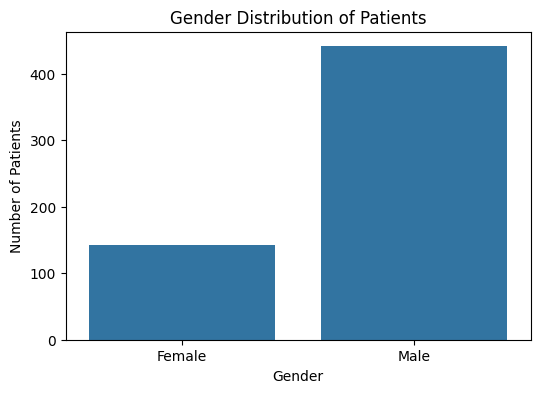

In [17]:
plt.figure(figsize=(6, 4))

sns.countplot(data=eda_df, x='Gender')

plt.title('Gender Distribution of Patients')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')

plt.show()

In [18]:
df['Age'].describe()

count    583.000000
mean      44.746141
std       16.189833
min        4.000000
25%       33.000000
50%       45.000000
75%       58.000000
max       90.000000
Name: Age, dtype: float64

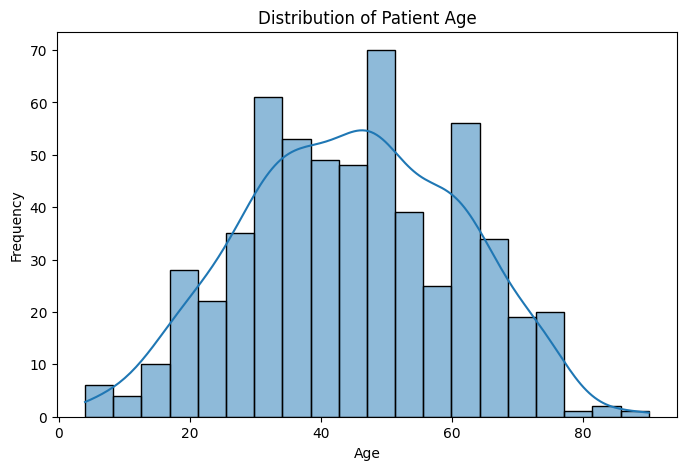

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', bins=20, kde=True)

plt.title('Distribution of Patient Age')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

## Exploratory Data Analysis (EDA)

### 1. Target Variable Analysis
The dataset contains 583 patient records.
416 records belong to patients with liver disease,
while 167 records belong to patients without liver disease.

The dataset shows class imbalance, with approximately
71.36% liver disease records and 28.64% non-liver disease records.

### 2. Gender Analysis
The dataset contains 441 male patients and 142 female patients.
Male records represent approximately 75.64% of the dataset.

### 3. Age Analysis
The average patient age is approximately 44.75 years.
The median age is 45 years.
The minimum age is 4 years and the maximum age is 90 years.

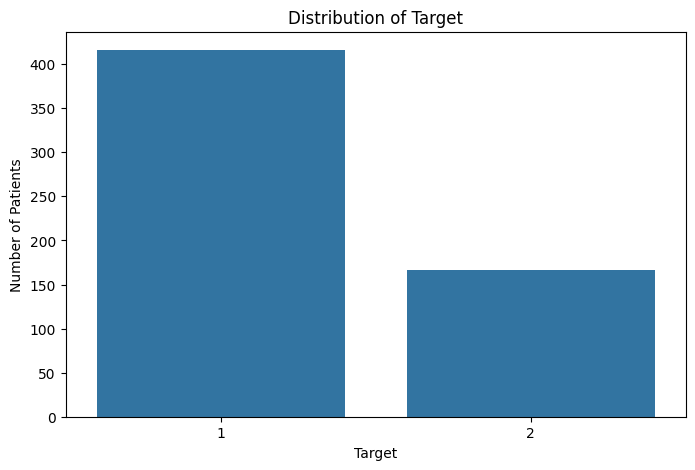

In [30]:
plt.figure(figsize=(8, 5))

sns.countplot(data=eda_df, x='Target')

plt.title('Distribution of Target')
plt.xlabel('Target')
plt.ylabel('Number of Patients')

plt.show()

### Target Distribution Analysis

The dataset contains 583 patient records.

Out of these:
- 416 patients (71.36%) have liver disease.
- 167 patients (28.64%) do not have liver disease.

The dataset shows class imbalance because the number of
liver disease records is significantly higher than the
number of non-liver disease records.

This imbalance will be considered during model development
and evaluation.

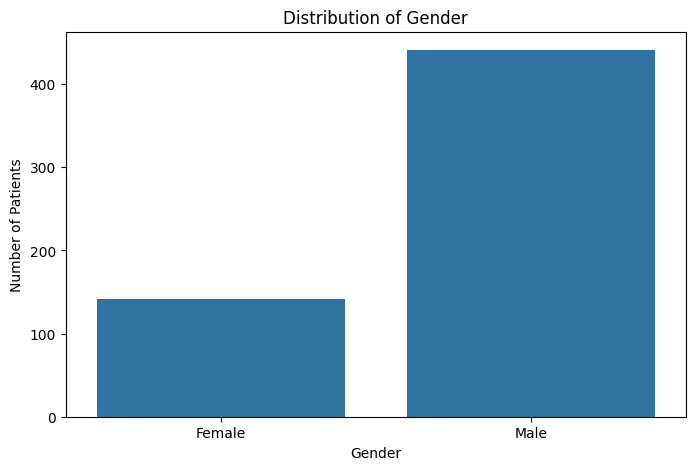

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(data=eda_df, x='Gender')

plt.title('Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')

plt.show()

In [33]:
df['Gender'].value_counts()

Gender
Male      441
Female    142
Name: count, dtype: int64

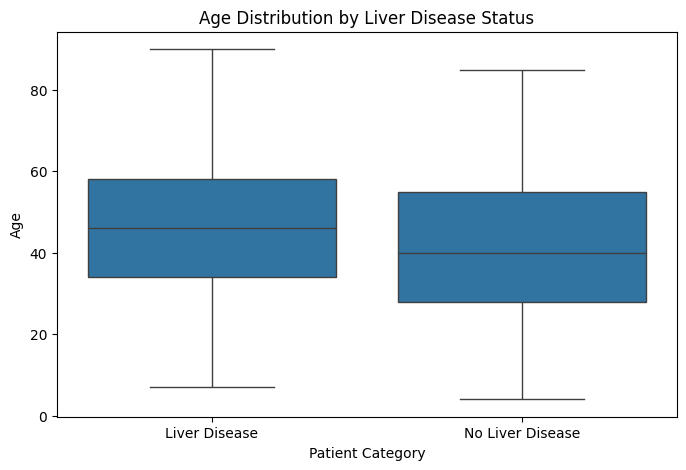

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Target_Label',
    y='Age'
)

plt.title('Age Distribution by Liver Disease Status')
plt.xlabel('Patient Category')
plt.ylabel('Age')

plt.show()

### Age vs Liver Disease Analysis

A box plot was used to compare the age distribution
between patients with and without liver disease.

The median age, interquartile range and outliers
were examined for both groups.

The findings help us understand whether age may
provide useful information for disease classification.

In [35]:
gender_target = pd.crosstab(
    eda_df['Gender'],
    eda_df['Target_Label']
)

gender_target

Target_Label,Liver Disease,No Liver Disease
Gender,,
Female,92,50
Male,324,117


In [39]:
gender_percentage = pd.crosstab(
    eda_df['Gender'],
    eda_df['Target_Label'],
    normalize='index'
) * 100

gender_percentage

Target_Label,Liver Disease,No Liver Disease
Gender,,
Female,64.788732,35.211268
Male,73.469388,26.530612


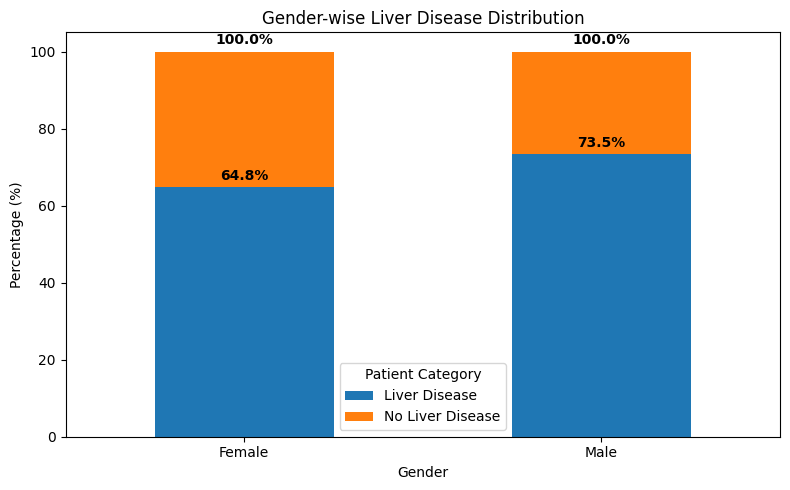

In [49]:
ax = gender_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3,
        fontsize=10,
        fontweight='bold'
    )

plt.title('Gender-wise Liver Disease Distribution')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')

plt.legend(title='Patient Category')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

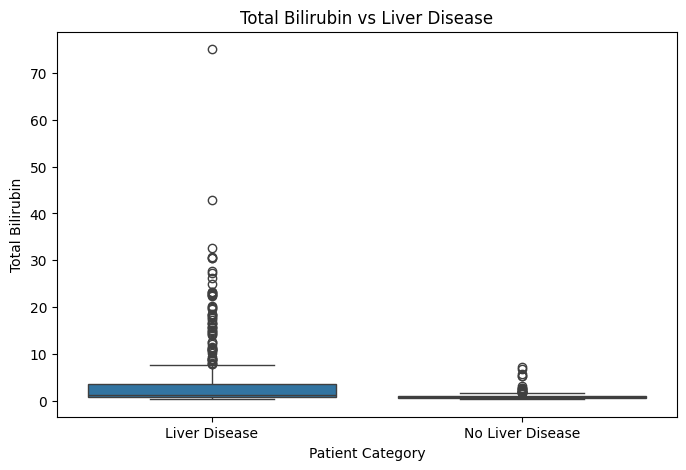

In [50]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Target_Label',
    y='Total_Bilirubin'
)

plt.title('Total Bilirubin vs Liver Disease')
plt.xlabel('Patient Category')
plt.ylabel('Total Bilirubin')

plt.show()

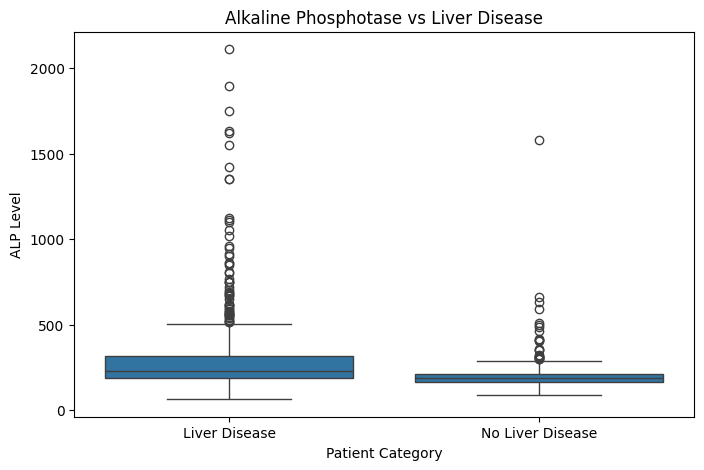

In [51]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Target_Label',
    y='Alkaline_Phosphotase'
)

plt.title('Alkaline Phosphotase vs Liver Disease')
plt.xlabel('Patient Category')
plt.ylabel('ALP Level')

plt.show()

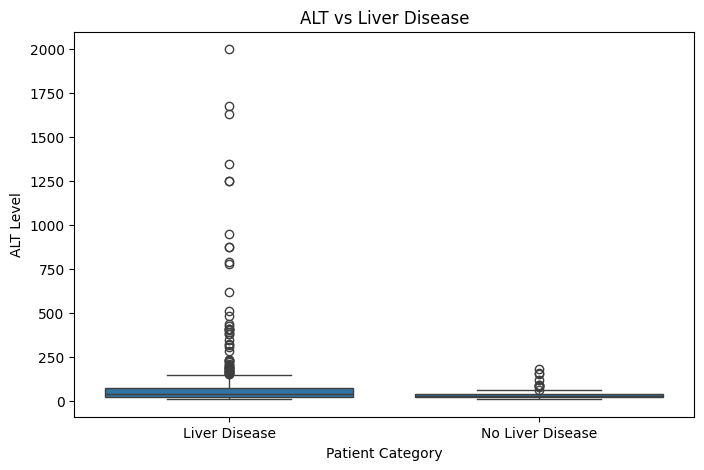

In [52]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Target_Label',
    y='Alamine_Aminotransferase'
)

plt.title('ALT vs Liver Disease')
plt.xlabel('Patient Category')
plt.ylabel('ALT Level')

plt.show()

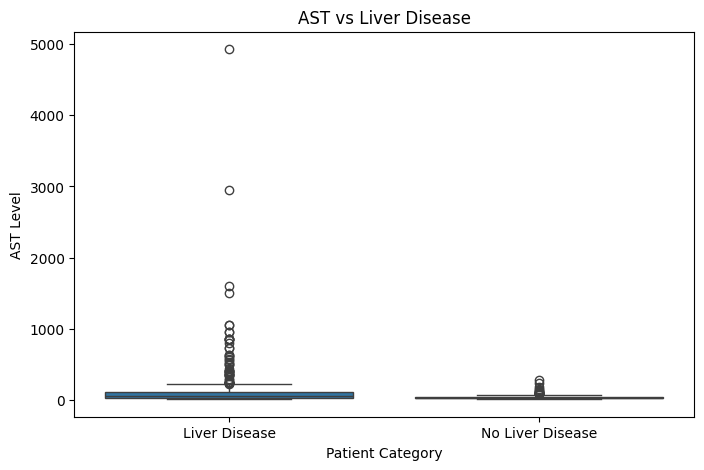

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Target_Label',
    y='Aspartate_Aminotransferase'
)

plt.title('AST vs Liver Disease')
plt.xlabel('Patient Category')
plt.ylabel('AST Level')

plt.show()

## Bivariate Analysis

## 1. Age vs Target
A box plot was used to compare age distributions
between liver disease and non-liver disease groups.

## 2. Gender vs Target
Cross-tabulation and a percentage-based stacked bar
chart were used to compare disease class proportions
across male and female records.

## 3. Total Bilirubin vs Target
A box plot was used to examine differences in
total bilirubin distributions across target classes.

## 4. Liver Enzymes vs Target
Box plots were generated for ALP, ALT and AST
to compare their distributions between target classes.

## Conclusion
The visual analysis helps identify potential
relationships between patient attributes and the
target variable. These observations will guide
the feature selection and model development stages.

In [54]:
numeric_df = df.select_dtypes(include=['number'])

numeric_df.head()

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [55]:
correlation_matrix = numeric_df.corr(method='pearson')

correlation_matrix

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target
Age,1.000000,0.011763,0.007529,0.080425,-0.086883,-0.019910,-0.187461,-0.265924,-0.216408,-0.137351
Total_Bilirubin,0.011763,1.000000,0.874618,0.206669,0.214065,0.237831,-0.008099,-0.222250,-0.206267,-0.220208
Direct_Bilirubin,0.007529,0.874618,1.000000,0.234939,0.233894,0.257544,-0.000139,-0.228531,-0.200125,-0.246046
Alkaline_Phosphotase,0.080425,0.206669,0.234939,1.000000,0.125680,0.167196,-0.028514,-0.165453,-0.234166,-0.184866
Alamine_Aminotransferase,-0.086883,0.214065,0.233894,0.125680,1.000000,0.791966,-0.042518,-0.029742,-0.002375,-0.163416
Aspartate_Aminotransferase,-0.019910,0.237831,0.257544,0.167196,0.791966,1.000000,-0.025645,-0.085290,-0.070040,-0.151934
Total_Proteins,-0.187461,-0.008099,-0.000139,-0.028514,-0.042518,-0.025645,1.000000,0.784053,0.234887,0.035008
Albumin,-0.265924,-0.222250,-0.228531,-0.165453,-0.029742,-0.085290,0.784053,1.000000,0.689632,0.161388
Albumin_and_Globulin_Ratio,-0.216408,-0.206267,-0.200125,-0.234166,-0.002375,-0.070040,0.234887,0.689632,1.000000,0.163131
Target,-0.137351,-0.220208,-0.246046,-0.184866,-0.163416,-0.151934,0.035008,0.161388,0.163131,1.000000


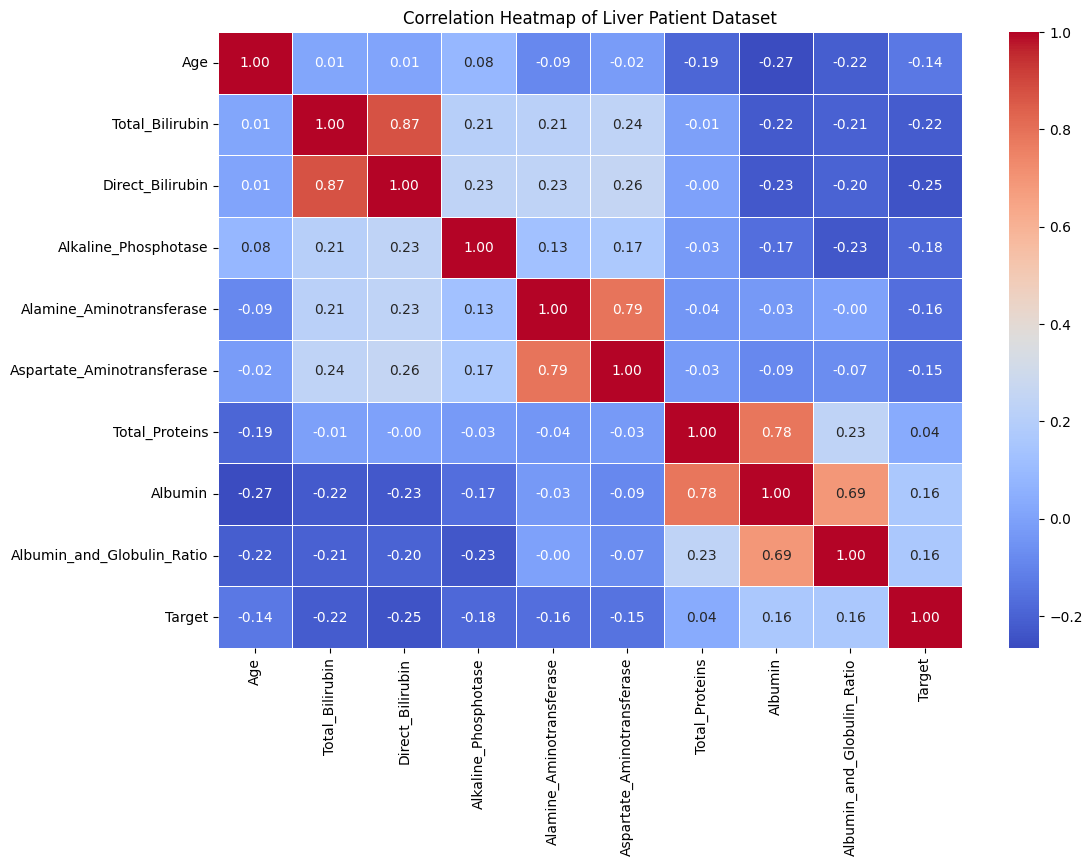

In [56]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Liver Patient Dataset')

plt.show()

In [57]:
correlation_matrix

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target
Age,1.000000,0.011763,0.007529,0.080425,-0.086883,-0.019910,-0.187461,-0.265924,-0.216408,-0.137351
Total_Bilirubin,0.011763,1.000000,0.874618,0.206669,0.214065,0.237831,-0.008099,-0.222250,-0.206267,-0.220208
Direct_Bilirubin,0.007529,0.874618,1.000000,0.234939,0.233894,0.257544,-0.000139,-0.228531,-0.200125,-0.246046
Alkaline_Phosphotase,0.080425,0.206669,0.234939,1.000000,0.125680,0.167196,-0.028514,-0.165453,-0.234166,-0.184866
Alamine_Aminotransferase,-0.086883,0.214065,0.233894,0.125680,1.000000,0.791966,-0.042518,-0.029742,-0.002375,-0.163416
Aspartate_Aminotransferase,-0.019910,0.237831,0.257544,0.167196,0.791966,1.000000,-0.025645,-0.085290,-0.070040,-0.151934
Total_Proteins,-0.187461,-0.008099,-0.000139,-0.028514,-0.042518,-0.025645,1.000000,0.784053,0.234887,0.035008
Albumin,-0.265924,-0.222250,-0.228531,-0.165453,-0.029742,-0.085290,0.784053,1.000000,0.689632,0.161388
Albumin_and_Globulin_Ratio,-0.216408,-0.206267,-0.200125,-0.234166,-0.002375,-0.070040,0.234887,0.689632,1.000000,0.163131
Target,-0.137351,-0.220208,-0.246046,-0.184866,-0.163416,-0.151934,0.035008,0.161388,0.163131,1.000000


In [58]:
corr_pairs = correlation_matrix.unstack()

corr_pairs = corr_pairs[
    (corr_pairs.abs() > 0.70) &
    (corr_pairs.abs() < 1.00)
]

corr_pairs

Total_Bilirubin             Direct_Bilirubin              0.874618
Direct_Bilirubin            Total_Bilirubin               0.874618
Alamine_Aminotransferase    Aspartate_Aminotransferase    0.791966
Aspartate_Aminotransferase  Alamine_Aminotransferase      0.791966
Total_Proteins              Albumin                       0.784053
Albumin                     Total_Proteins                0.784053
dtype: float64

In [59]:
target_correlation = correlation_matrix['Target'].sort_values(
    ascending=False
)

target_correlation

Target                        1.000000
Albumin_and_Globulin_Ratio    0.163131
Albumin                       0.161388
Total_Proteins                0.035008
Age                          -0.137351
Aspartate_Aminotransferase   -0.151934
Alamine_Aminotransferase     -0.163416
Alkaline_Phosphotase         -0.184866
Total_Bilirubin              -0.220208
Direct_Bilirubin             -0.246046
Name: Target, dtype: float64

## Methodology
Pearson correlation was used to calculate the
correlation coefficients between numerical features.

A correlation matrix and heatmap were generated
using Pandas and Seaborn.

## Observations
1. The correlation matrix was examined to identify
   positive and negative relationships.

2. Highly correlated feature pairs were investigated
   for potential multicollinearity.

3. Correlations between numerical features and the
   target variable were examined.

## Conclusion
Correlation analysis provides insights into
relationships between numerical variables and helps
guide further feature investigation and model development.

In [60]:
orr_pairs = correlation_matrix.unstack()

corr_pairs = corr_pairs[
    (corr_pairs.abs() > 0.70) &
    (corr_pairs.abs() < 1.00)
]

corr_pairs = corr_pairs.sort_values(
    ascending=False
)

corr_pairs

Total_Bilirubin             Direct_Bilirubin              0.874618
Direct_Bilirubin            Total_Bilirubin               0.874618
Alamine_Aminotransferase    Aspartate_Aminotransferase    0.791966
Aspartate_Aminotransferase  Alamine_Aminotransferase      0.791966
Total_Proteins              Albumin                       0.784053
Albumin                     Total_Proteins                0.784053
dtype: float64

In [61]:
df_clean = df.copy()

In [62]:
df_clean.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Target                        0
dtype: int64

In [63]:
median_value = df_clean['Albumin_and_Globulin_Ratio'].median()

print("Median value:", median_value)

Median value: 0.93


In [64]:
df_clean['Albumin_and_Globulin_Ratio'] = (
    df_clean['Albumin_and_Globulin_Ratio'].fillna(median_value)
)

In [65]:
df_clean.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Proteins                0
Albumin                       0
Albumin_and_Globulin_Ratio    0
Target                        0
dtype: int64

In [66]:
print("Original dataset shape:", df.shape)

print("Cleaned dataset shape:", df_clean.shape)

print("Missing values before:", df.isnull().sum().sum())

print("Missing values after:", df_clean.isnull().sum().sum())

Original dataset shape: (583, 11)
Cleaned dataset shape: (583, 11)
Missing values before: 4
Missing values after: 0


In [67]:
numeric_df = df_clean.select_dtypes(include=['number'])

numeric_df.head()

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [68]:
numeric_features = numeric_df.drop(columns=['Target'])

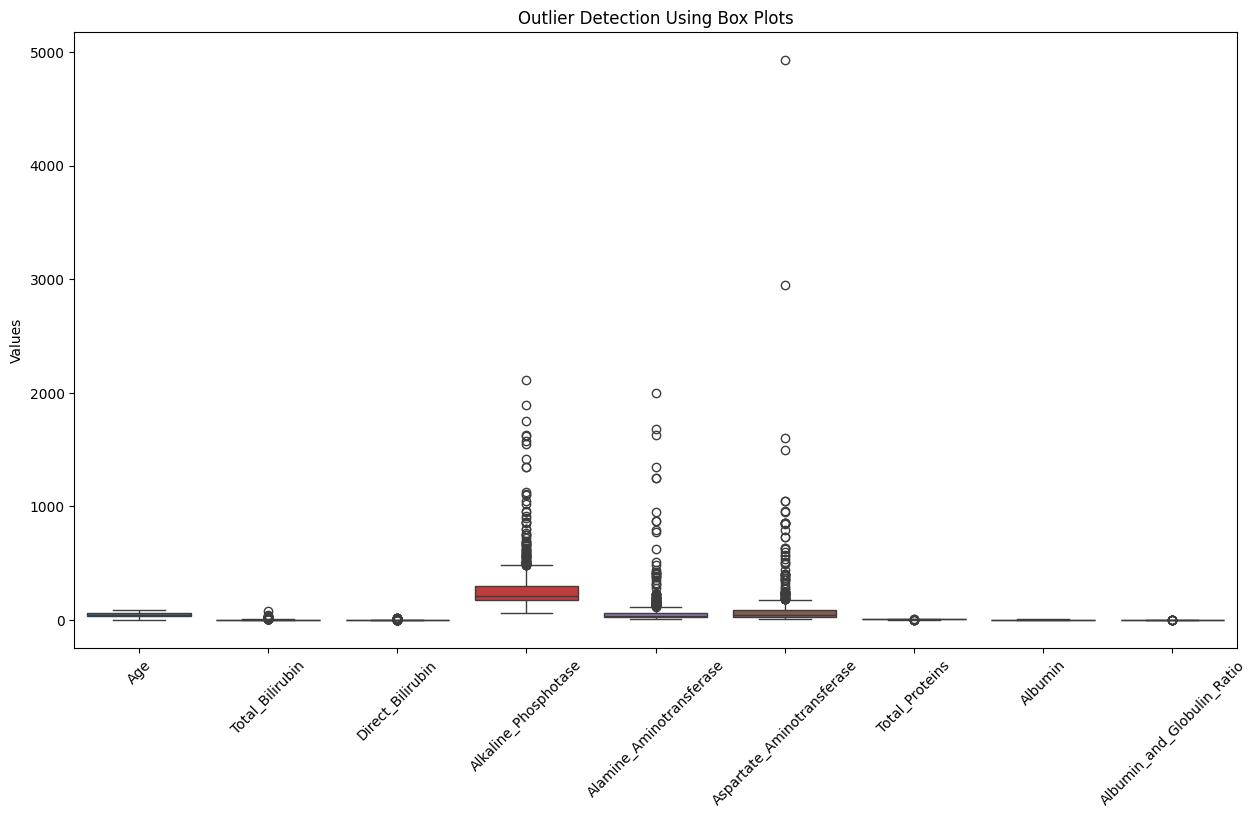

In [69]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=numeric_features)

plt.title('Outlier Detection Using Box Plots')
plt.xticks(rotation=45)
plt.ylabel('Values')

plt.show()

In [72]:
Q1 = numeric_features.quantile(0.25)

Q3 = numeric_features.quantile(0.75)

IQR = Q3 - Q1

print("Q1 Values:")
print(Q1)

print("\nQ3 Values:")
print(Q3)

print("\nIQR Values:")
print(IQR)

Q1 Values:
Age                            33.0
Total_Bilirubin                 0.8
Direct_Bilirubin                0.2
Alkaline_Phosphotase          175.5
Alamine_Aminotransferase       23.0
Aspartate_Aminotransferase     25.0
Total_Proteins                  5.8
Albumin                         2.6
Albumin_and_Globulin_Ratio      0.7
Name: 0.25, dtype: float64

Q3 Values:
Age                            58.0
Total_Bilirubin                 2.6
Direct_Bilirubin                1.3
Alkaline_Phosphotase          298.0
Alamine_Aminotransferase       60.5
Aspartate_Aminotransferase     87.0
Total_Proteins                  7.2
Albumin                         3.8
Albumin_and_Globulin_Ratio      1.1
Name: 0.75, dtype: float64

IQR Values:
Age                            25.0
Total_Bilirubin                 1.8
Direct_Bilirubin                1.1
Alkaline_Phosphotase          122.5
Alamine_Aminotransferase       37.5
Aspartate_Aminotransferase     62.0
Total_Proteins                  1.4
Albumin   

In [73]:
lower_bound = Q1 - (1.5 * IQR)

upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:")
print(lower_bound)

print("\nUpper Bound:")
print(upper_bound)

Lower Bound:
Age                           -4.50
Total_Bilirubin               -1.90
Direct_Bilirubin              -1.45
Alkaline_Phosphotase          -8.25
Alamine_Aminotransferase     -33.25
Aspartate_Aminotransferase   -68.00
Total_Proteins                 3.70
Albumin                        0.80
Albumin_and_Globulin_Ratio     0.10
dtype: float64

Upper Bound:
Age                            95.50
Total_Bilirubin                 5.30
Direct_Bilirubin                2.95
Alkaline_Phosphotase          481.75
Alamine_Aminotransferase      116.75
Aspartate_Aminotransferase    180.00
Total_Proteins                  9.30
Albumin                         5.60
Albumin_and_Globulin_Ratio      1.70
dtype: float64


In [74]:
outlier_condition = (
    (numeric_features < lower_bound) |
    (numeric_features > upper_bound)
)

outlier_count = outlier_condition.sum()

print("Outlier Count:")
print(outlier_count)

Outlier Count:
Age                            0
Total_Bilirubin               84
Direct_Bilirubin              81
Alkaline_Phosphotase          69
Alamine_Aminotransferase      73
Aspartate_Aminotransferase    66
Total_Proteins                 8
Albumin                        0
Albumin_and_Globulin_Ratio    10
dtype: int64


In [75]:
outlier_summary = pd.DataFrame({
    'Outlier_Count': outlier_count,
    'Outlier_Percentage': (
        outlier_count / len(numeric_features)
    ) * 100
})

outlier_summary

,Outlier_Count,Outlier_Percentage
Age,0,0.000000
Total_Bilirubin,84,14.408233
Direct_Bilirubin,81,13.893654
Alkaline_Phosphotase,69,11.835334
Alamine_Aminotransferase,73,12.521441
Aspartate_Aminotransferase,66,11.320755
Total_Proteins,8,1.372213
Albumin,0,0.000000
Albumin_and_Globulin_Ratio,10,1.715266


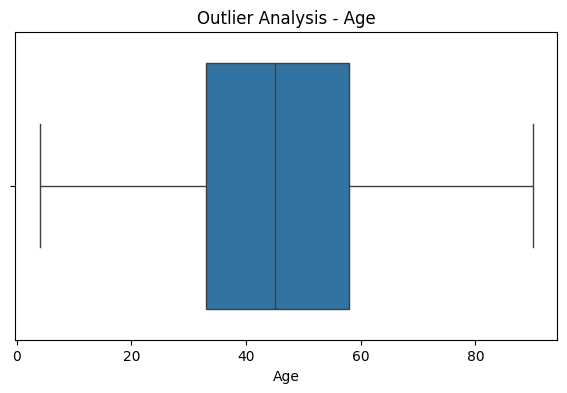

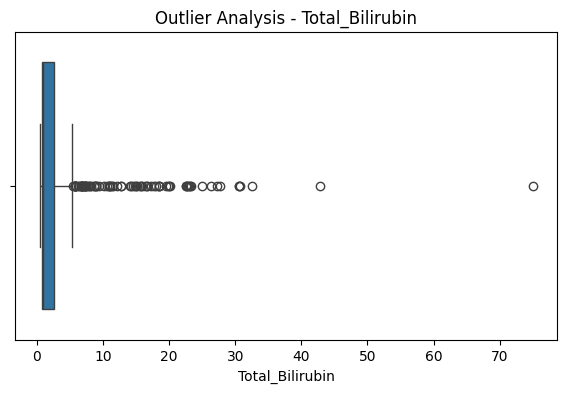

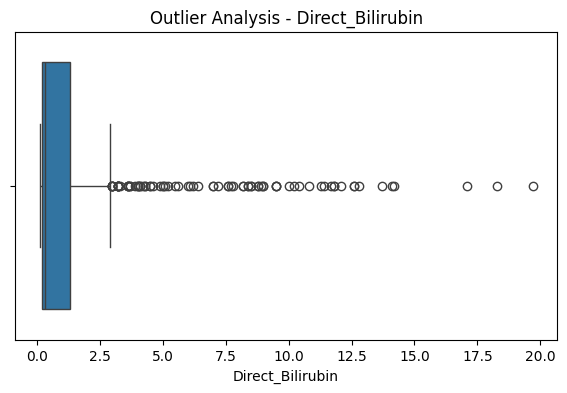

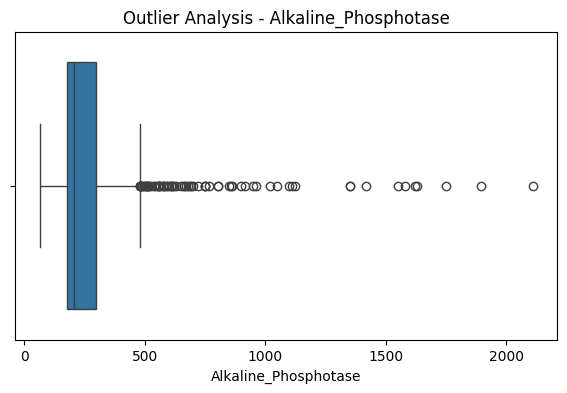

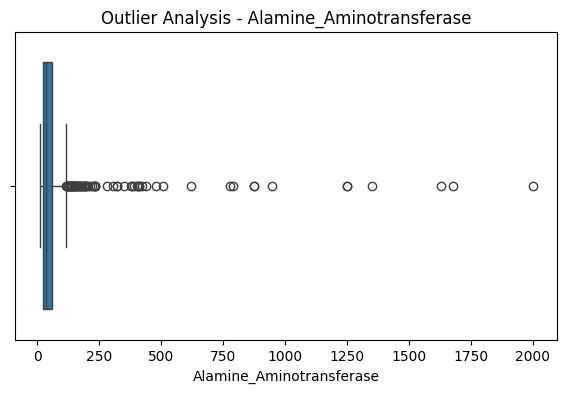

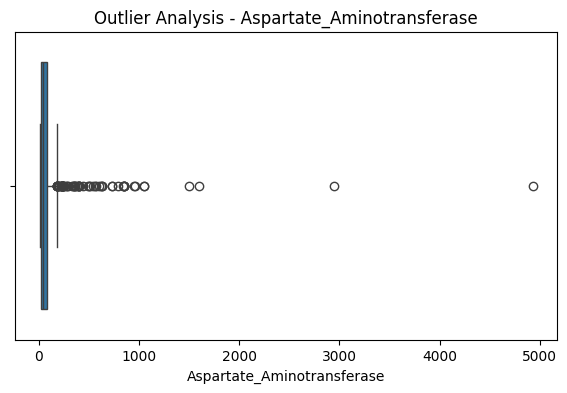

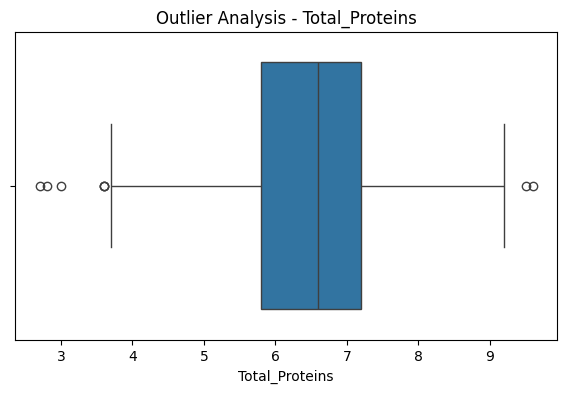

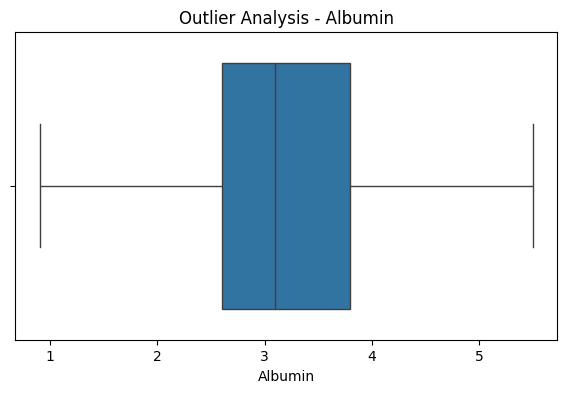

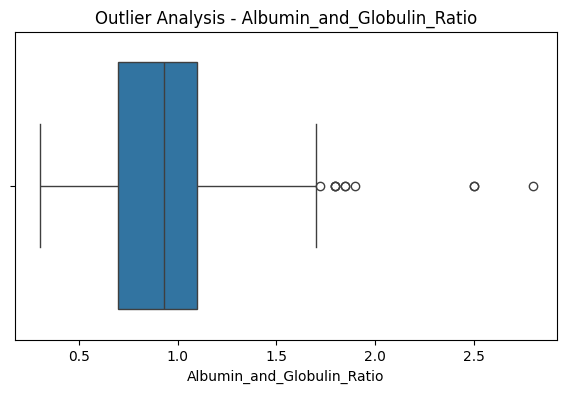

In [76]:
features = numeric_features.columns

for feature in features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(x=numeric_features[feature])

    plt.title(f'Outlier Analysis - {feature}')

    plt.xlabel(feature)

    plt.show()

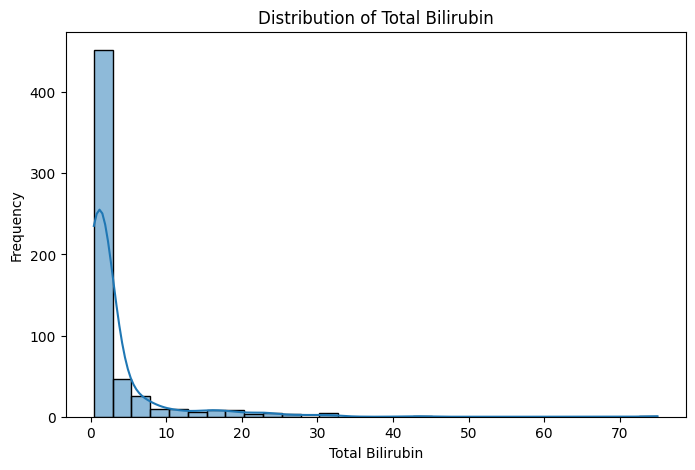

In [77]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Total_Bilirubin',
    bins=30,
    kde=True
)

plt.title('Distribution of Total Bilirubin')
plt.xlabel('Total Bilirubin')
plt.ylabel('Frequency')

plt.show()

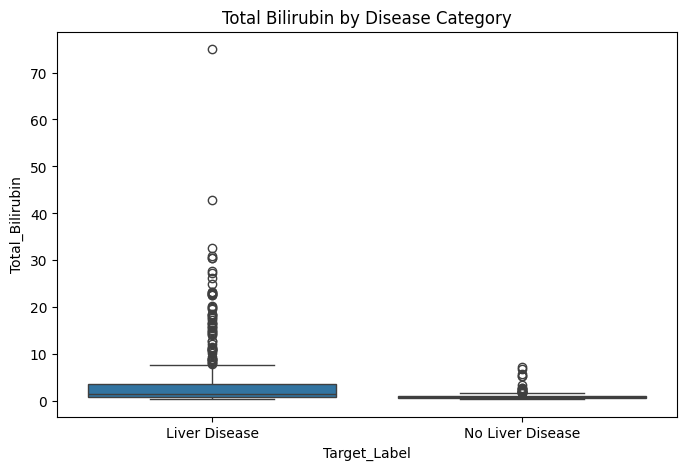

In [78]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Target_Label',
    y='Total_Bilirubin'
)

plt.title('Total Bilirubin by Disease Category')

plt.show()

In [79]:
df_clean['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [80]:
from sklearn.preprocessing import OneHotEncoder

In [81]:
encoder = OneHotEncoder(
    drop='if_binary',
    handle_unknown='ignore',
    sparse_output=False
)

In [82]:
gender_encoded = encoder.fit_transform(
    df_clean[['Gender']]
)

In [83]:
gender_df = pd.DataFrame(
    gender_encoded,
    columns=encoder.get_feature_names_out(['Gender']),
    index=df_clean.index
)

gender_df.head()

,Gender_Male
0,0.0
1,1.0
2,1.0
3,1.0
4,1.0


In [84]:
df_encoded = pd.concat(
    [
        df_clean.drop(columns=['Gender']),
        gender_df
    ],
    axis=1
)

df_encoded.head()

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Target,Gender_Male
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90,1,0.0
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74,1,1.0
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89,1,1.0
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00,1,1.0
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40,1,1.0


In [85]:
print("Original shape:", df_clean.shape)
print("Encoded shape:", df_encoded.shape)

Original shape: (583, 11)
Encoded shape: (583, 11)


In [86]:
X = df_encoded.drop(columns=['Target'])

y = df_encoded['Target']

In [87]:
print("Features shape:", X.shape)

print("Target shape:", y.shape)

Features shape: (583, 10)
Target shape: (583,)


In [90]:
X.head()

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,Gender_Male
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90,0.0
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74,1.0
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89,1.0
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00,1.0
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40,1.0


In [92]:
X.shape

(583, 10)

In [93]:
from sklearn.preprocessing import StandardScaler

In [100]:
from sklearn.model_selection import train_test_split

In [101]:
# Independent features
X = df.drop(columns=['Target'])

# Dependent variable
y = df['Target'].map({
    1: 1,  # Liver disease
    2: 0   # No liver disease
})

In [102]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [103]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (466, 10)
X_test: (117, 10)
y_train: (466,)
y_test: (117,)


In [104]:
print("Original target distribution:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Original target distribution:
Target
1    71.35506
0    28.64494
Name: proportion, dtype: float64

Training target distribution:
Target
1    71.459227
0    28.540773
Name: proportion, dtype: float64

Testing target distribution:
Target
1    70.940171
0    29.059829
Name: proportion, dtype: float64


In [106]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [108]:
numeric_columns = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin', 'Albumin_and_Globulin_Ratio']
Categorical columns: ['Gender']


In [109]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [110]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='if_binary',
        handle_unknown='ignore'
    ))
])

In [111]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

In [112]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [113]:
print("Training data:", X_train_processed.shape)

print("Testing data:", X_test_processed.shape)

Training data: (466, 10)
Testing data: (117, 10)


In [114]:
X_train.shape
X_test.shape
X_train_processed.shape
X_test_processed.shape

(117, 10)

In [115]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train shape: (466, 10)
X_test shape: (117, 10)
X_train_processed shape: (466, 10)
X_test_processed shape: (117, 10)


In [116]:
from sklearn.linear_model import LogisticRegression

In [118]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [119]:
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [120]:
y_pred = logistic_model.predict(X_test)

y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1])

In [121]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(15)

,Actual,Predicted
0,1,1
1,1,1
2,0,1
3,1,1
4,1,1
5,1,1
6,0,1
7,0,1
8,1,1
9,0,1


In [122]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 73.50427350427351 %


In [123]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 6 28]
 [ 3 80]]


In [124]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['No Liver Disease', 'Liver Disease']
))

                  precision    recall  f1-score   support

No Liver Disease       0.67      0.18      0.28        34
   Liver Disease       0.74      0.96      0.84        83

        accuracy                           0.74       117
       macro avg       0.70      0.57      0.56       117
    weighted avg       0.72      0.74      0.68       117



In [125]:
logistic_model_weighted = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [126]:
logistic_model_weighted.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [127]:
y_pred_weighted = logistic_model_weighted.predict(X_test)

In [128]:
print(classification_report(
    y_test,
    y_pred_weighted,
    target_names=['No Liver Disease', 'Liver Disease']
))

                  precision    recall  f1-score   support

No Liver Disease       0.53      0.85      0.65        34
   Liver Disease       0.92      0.69      0.79        83

        accuracy                           0.74       117
       macro avg       0.72      0.77      0.72       117
    weighted avg       0.81      0.74      0.75       117



In [129]:
from sklearn.ensemble import RandomForestClassifier

In [130]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer_rf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer_rf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='if_binary',
        handle_unknown='ignore'
    ))
])

preprocessor_rf = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_rf, numeric_columns),
        ('cat', categorical_transformer_rf, categorical_columns)
    ]
)

In [131]:
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor_rf),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

In [132]:
random_forest_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [133]:
y_pred_rf = random_forest_model.predict(X_test)

y_pred_rf

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1])

In [134]:
from sklearn.metrics import accuracy_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      accuracy_rf * 100, "%")

Random Forest Accuracy: 76.06837606837607 %


In [135]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[13 21]
 [ 7 76]]


In [136]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.65      0.38      0.48        34
   Liver Disease       0.78      0.92      0.84        83

        accuracy                           0.76       117
       macro avg       0.72      0.65      0.66       117
    weighted avg       0.74      0.76      0.74       117



In [137]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

models = {
    'Logistic Regression': y_pred,
    'Weighted Logistic Regression': y_pred_weighted,
    'Random Forest': y_pred_rf
}

for model_name, predictions in models.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Balanced Accuracy': balanced_accuracy_score(y_test, predictions),
        'Disease Precision': precision_score(
            y_test, predictions, pos_label=1
        ),
        'Disease Recall': recall_score(
            y_test, predictions, pos_label=1
        ),
        'Disease F1': f1_score(
            y_test, predictions, pos_label=1
        ),
        'No Disease Recall': recall_score(
            y_test, predictions, pos_label=0
        )
    })

model_comparison_rf = pd.DataFrame(results)

model_comparison_rf.round(3)


,Model,Accuracy,Balanced Accuracy,Disease Precision,Disease Recall,Disease F1,No Disease Recall
0,Logistic Regression,0.735,0.570,0.741,0.964,0.838,0.176
1,Weighted Logistic Regression,0.735,0.770,0.919,0.687,0.786,0.853
2,Random Forest,0.761,0.649,0.784,0.916,0.844,0.382


In [138]:
feature_importance = (
    random_forest_model
    .named_steps['classifier']
    .feature_importances_
)

feature_names = (
    random_forest_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
3,num__Alkaline_Phosphotase,0.145386
0,num__Age,0.138532
5,num__Aspartate_Aminotransferase,0.133087
4,num__Alamine_Aminotransferase,0.126368
7,num__Albumin,0.101940
6,num__Total_Proteins,0.093716
1,num__Total_Bilirubin,0.091795
8,num__Albumin_and_Globulin_Ratio,0.079950
2,num__Direct_Bilirubin,0.070394
9,cat__Gender_Male,0.018832


In [139]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [140]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [141]:
models = {
    'Logistic Regression': logistic_model,

    'Weighted Logistic Regression': logistic_model_weighted,

    'Random Forest': random_forest_model
}

scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

cv_comparison.round(3)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.728,0.566,0.744,0.943,0.832
1,Weighted Logistic Regression,0.612,0.665,0.869,0.541,0.663
2,Random Forest,0.719,0.592,0.761,0.889,0.819


In [142]:
cv_detailed_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_detailed_results.append({
        'Model': name,

        'Accuracy Mean': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),

        'Balanced Accuracy Mean':
            scores['test_balanced_accuracy'].mean(),

        'Balanced Accuracy Std':
            scores['test_balanced_accuracy'].std(),

        'Recall Mean': scores['test_recall'].mean(),
        'Recall Std': scores['test_recall'].std()
    })

cv_detailed_df = pd.DataFrame(cv_detailed_results)

cv_detailed_df.round(3)

,Model,Accuracy Mean,Accuracy Std,Balanced Accuracy Mean,Balanced Accuracy Std,Recall Mean,Recall Std
0,Logistic Regression,0.728,0.031,0.566,0.030,0.943,0.035
1,Weighted Logistic Regression,0.612,0.040,0.665,0.037,0.541,0.067
2,Random Forest,0.719,0.036,0.592,0.057,0.889,0.036


In [143]:
from sklearn.tree import DecisionTreeClassifier

In [144]:
decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor_rf),

    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        random_state=42
    ))
])

In [145]:
decision_tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [146]:
y_pred_dt = decision_tree_model.predict(X_test)

y_pred_dt

array([0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 1, 1])

In [147]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:",
      accuracy_dt * 100, "%")

Decision Tree Accuracy: 54.700854700854705 %


In [149]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_dt

array([[ 7, 27],
       [26, 57]])

In [150]:
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.21      0.21      0.21        34
   Liver Disease       0.68      0.69      0.68        83

        accuracy                           0.55       117
       macro avg       0.45      0.45      0.45       117
    weighted avg       0.54      0.55      0.54       117



In [151]:
decision_tree_tuned = Pipeline(steps=[
    ('preprocessor', preprocessor_rf),

    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=4,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

In [152]:
decision_tree_tuned.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [153]:
y_pred_dt_tuned = decision_tree_tuned.predict(X_test)

In [154]:
accuracy_dt_tuned = accuracy_score(
    y_test,
    y_pred_dt_tuned
)

print("Tuned Decision Tree Accuracy:",
      accuracy_dt_tuned * 100, "%")

Tuned Decision Tree Accuracy: 68.37606837606837 %


In [155]:
print(classification_report(
    y_test,
    y_pred_dt_tuned,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.40      0.18      0.24        34
   Liver Disease       0.73      0.89      0.80        83

        accuracy                           0.68       117
       macro avg       0.56      0.53      0.52       117
    weighted avg       0.63      0.68      0.64       117



In [156]:
max_depth=4
min_samples_split=10
min_samples_leaf=5

In [157]:
all_models = {
    'Logistic Regression': y_pred,
    'Weighted Logistic Regression': y_pred_weighted,
    'Random Forest': y_pred_rf,
    'Original Decision Tree': y_pred_dt,
    'Restricted Decision Tree': y_pred_dt_tuned
}

comparison_results = []

for name, predictions in all_models.items():

    comparison_results.append({
        'Model': name,

        'Accuracy': accuracy_score(
            y_test, predictions
        ),

        'Balanced Accuracy': balanced_accuracy_score(
            y_test, predictions
        ),

        'Disease Precision': precision_score(
            y_test, predictions, pos_label=1
        ),

        'Disease Recall': recall_score(
            y_test, predictions, pos_label=1
        ),

        'Disease F1': f1_score(
            y_test, predictions, pos_label=1
        ),

        'No Disease Recall': recall_score(
            y_test, predictions, pos_label=0
        )
    })

final_comparison = pd.DataFrame(comparison_results)

final_comparison.round(3)

,Model,Accuracy,Balanced Accuracy,Disease Precision,Disease Recall,Disease F1,No Disease Recall
0,Logistic Regression,0.735,0.570,0.741,0.964,0.838,0.176
1,Weighted Logistic Regression,0.735,0.770,0.919,0.687,0.786,0.853
2,Random Forest,0.761,0.649,0.784,0.916,0.844,0.382
3,Original Decision Tree,0.547,0.446,0.679,0.687,0.683,0.206
4,Restricted Decision Tree,0.684,0.534,0.725,0.892,0.800,0.176


In [158]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [160]:
numeric_transformer_knn = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer_knn = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='if_binary',
        handle_unknown='ignore'
    ))
])

preprocessor_knn = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_knn, numeric_columns),
        ('cat', categorical_transformer_knn, categorical_columns)
    ]
)

In [161]:
knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor_knn),

    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        metric='euclidean',
        weights='uniform'
    ))
])

In [162]:
knn_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [163]:
y_pred_knn = knn_model.predict(X_test)

y_pred_knn

array([1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1])

In [164]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:",
      accuracy_knn * 100, "%")

KNN Accuracy: 68.37606837606837 %


In [165]:
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_knn

array([[ 9, 25],
       [12, 71]])

In [166]:
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.43      0.26      0.33        34
   Liver Disease       0.74      0.86      0.79        83

        accuracy                           0.68       117
       macro avg       0.58      0.56      0.56       117
    weighted avg       0.65      0.68      0.66       117



In [167]:
from sklearn.model_selection import cross_val_score

k_values = [3, 5, 7, 9, 11, 13, 15]

knn_results = []

for k in k_values:

    model = Pipeline(steps=[
        ('preprocessor', preprocessor_knn),

        ('classifier', KNeighborsClassifier(
            n_neighbors=k,
            metric='euclidean'
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='balanced_accuracy',
        n_jobs=-1
    )

    knn_results.append({
        'K Value': k,
        'Mean Balanced Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

knn_results_df = pd.DataFrame(knn_results)

knn_results_df.round(3)

,K Value,Mean Balanced Accuracy,Standard Deviation
0,3,0.531,0.039
1,5,0.558,0.037
2,7,0.553,0.027
3,9,0.547,0.040
4,11,0.532,0.020
5,13,0.535,0.023
6,15,0.506,0.026


In [168]:
knn_model_tuned = Pipeline(steps=[
    ('preprocessor', preprocessor_knn),

    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        metric='euclidean',
        weights='uniform'
    ))
])

In [169]:
knn_model_tuned.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [170]:
y_pred_knn_tuned = knn_model_tuned.predict(X_test)

In [171]:
print(classification_report(
    y_test,
    y_pred_knn_tuned,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.43      0.26      0.33        34
   Liver Disease       0.74      0.86      0.79        83

        accuracy                           0.68       117
       macro avg       0.58      0.56      0.56       117
    weighted avg       0.65      0.68      0.66       117



In [172]:
print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_test, y_pred_knn_tuned)
)

Balanced Accuracy: 0.5600637845499645


In [174]:
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn_tuned
)

print(cm_knn)

[[ 9 25]
 [12 71]]


In [175]:
from sklearn.svm import SVC

In [176]:
svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor_knn),

    ('classifier', SVC(
        kernel='linear',
        C=1.0,
        random_state=42
    ))
])

In [177]:
svm_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [178]:
y_pred_svm = svm_model.predict(X_test)

y_pred_svm

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1])

In [179]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:",
      accuracy_svm * 100, "%")

SVM Accuracy: 70.94017094017094 %


In [180]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_svm

array([[ 0, 34],
       [ 0, 83]])

In [181]:
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.00      0.00      0.00        34
   Liver Disease       0.71      1.00      0.83        83

        accuracy                           0.71       117
       macro avg       0.35      0.50      0.41       117
    weighted avg       0.50      0.71      0.59       117



/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [182]:
from sklearn.model_selection import cross_validate

kernels = ['linear', 'rbf']

svm_results = []

for kernel in kernels:

    model = Pipeline(steps=[
        ('preprocessor', preprocessor_knn),

        ('classifier', SVC(
            kernel=kernel,
            C=1.0
        ))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='balanced_accuracy',
        n_jobs=-1
    )

    svm_results.append({
        'Kernel': kernel,
        'Mean Balanced Accuracy': scores['test_score'].mean(),
        'Standard Deviation': scores['test_score'].std()
    })

svm_results_df = pd.DataFrame(svm_results)

svm_results_df.round(3)

,Kernel,Mean Balanced Accuracy,Standard Deviation
0,linear,0.5,0.0
1,rbf,0.5,0.0


In [183]:
print(y_train.value_counts())

print("\nClass percentages:")

print(
    y_train.value_counts(normalize=True) * 100
)

Target
1    333
0    133
Name: count, dtype: int64

Class percentages:
Target
1    71.459227
0    28.540773
Name: proportion, dtype: float64


In [184]:
print("Actual distribution:")

print(pd.Series(y_test).value_counts())

print("\nPredicted distribution:")

print(pd.Series(y_pred_svm).value_counts())

Actual distribution:
Target
1    83
0    34
Name: count, dtype: int64

Predicted distribution:
1    117
Name: count, dtype: int64


In [185]:
print(confusion_matrix(y_test, y_pred_svm))

[[ 0 34]
 [ 0 83]]


In [186]:
svm_balanced = Pipeline(steps=[
    ('preprocessor', preprocessor_knn),

    ('classifier', SVC(
        kernel='linear',
        C=1.0,
        class_weight='balanced',
        random_state=42
    ))
])

In [187]:
svm_balanced.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [188]:
y_pred_svm_balanced = svm_balanced.predict(X_test)

In [189]:
print(classification_report(
    y_test,
    y_pred_svm_balanced,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.50      0.97      0.66        34
   Liver Disease       0.98      0.60      0.75        83

        accuracy                           0.71       117
       macro avg       0.74      0.79      0.70       117
    weighted avg       0.84      0.71      0.72       117



In [190]:
print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred_svm_balanced
    )
)

Balanced Accuracy: 0.7864989369241673


In [191]:
svm_comparison = pd.DataFrame({

    'Model': [
        'Original SVM',
        'Balanced SVM'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_svm_balanced)
    ],

    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, y_pred_svm),
        balanced_accuracy_score(y_test, y_pred_svm_balanced)
    ],

    'Disease Recall': [
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_svm_balanced)
    ],

    'No Disease Recall': [
        recall_score(y_test, y_pred_svm, pos_label=0),
        recall_score(y_test, y_pred_svm_balanced, pos_label=0)
    ]
})

svm_comparison.round(3)

,Model,Accuracy,Balanced Accuracy,Disease Recall,No Disease Recall
0,Original SVM,0.709,0.500,1.000,0.000
1,Balanced SVM,0.709,0.786,0.602,0.971


In [192]:
balanced_svm_cv = cross_validate(
    svm_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'balanced_accuracy': 'balanced_accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

print("Mean Balanced Accuracy:",
      balanced_svm_cv['test_balanced_accuracy'].mean())

print("Standard Deviation:",
      balanced_svm_cv['test_balanced_accuracy'].std())

print("Mean Disease Recall:",
      balanced_svm_cv['test_recall'].mean())

Mean Balanced Accuracy: 0.6512861102413341
Standard Deviation: 0.04002563144149592
Mean Disease Recall: 0.4598371777476255


In [193]:
fold_scores = balanced_svm_cv[
    'test_balanced_accuracy'
]

for i, score in enumerate(fold_scores, 1):

    print(
        f"Fold {i}: {score:.3f}"
    )

Fold 1: 0.646
Fold 2: 0.711
Fold 3: 0.599
Fold 4: 0.679
Fold 5: 0.621


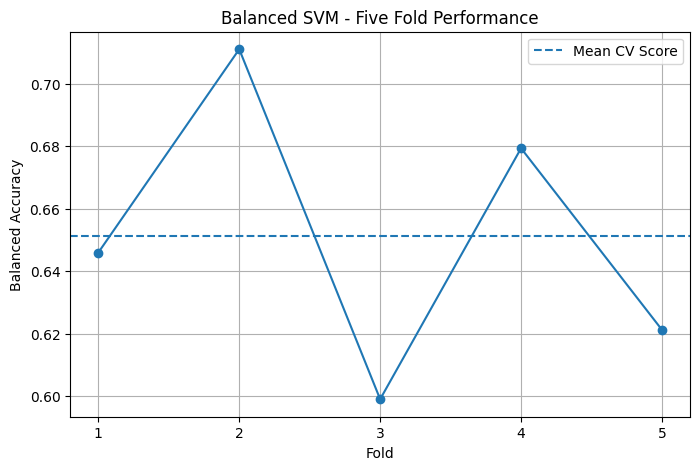

In [194]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    fold_scores,
    marker='o'
)

plt.axhline(
    fold_scores.mean(),
    linestyle='--',
    label='Mean CV Score'
)

plt.xlabel('Fold')
plt.ylabel('Balanced Accuracy')
plt.title('Balanced SVM - Five Fold Performance')

plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)

plt.show()

In [195]:
from sklearn.ensemble import GradientBoostingClassifier

In [196]:
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor_rf),

    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [197]:
gb_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [198]:
y_pred_gb = gb_model.predict(X_test)

y_pred_gb

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1])

In [199]:
accuracy_gb = accuracy_score(
    y_test,
    y_pred_gb
)

print("Gradient Boosting Accuracy:",
      accuracy_gb * 100, "%")

Gradient Boosting Accuracy: 68.37606837606837 %


In [200]:
balanced_gb = balanced_accuracy_score(
    y_test,
    y_pred_gb
)

print("Balanced Accuracy:",
      balanced_gb * 100, "%")

Balanced Accuracy: 54.27002126151665 %


In [201]:
cm_gb = confusion_matrix(
    y_test,
    y_pred_gb
)
cm_gb

array([[ 7, 27],
       [10, 73]])

In [202]:
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.41      0.21      0.27        34
   Liver Disease       0.73      0.88      0.80        83

        accuracy                           0.68       117
       macro avg       0.57      0.54      0.54       117
    weighted avg       0.64      0.68      0.65       117



In [203]:
gb_cv = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'balanced_accuracy': 'balanced_accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

print(
    "Mean Balanced Accuracy:",
    gb_cv['test_balanced_accuracy'].mean()
)

print(
    "Standard Deviation:",
    gb_cv['test_balanced_accuracy'].std()
)

print(
    "Mean Disease Recall:",
    gb_cv['test_recall'].mean()
)

Mean Balanced Accuracy: 0.6020416565192683
Standard Deviation: 0.039583552802485183
Mean Disease Recall: 0.8647670737222976


In [204]:
train_accuracy_gb = gb_model.score(
    X_train,
    y_train
)

test_accuracy_gb = gb_model.score(
    X_test,
    y_test
)

print("Training Accuracy:",
      train_accuracy_gb)

print("Testing Accuracy:",
      test_accuracy_gb)

Training Accuracy: 0.9420600858369099
Testing Accuracy: 0.6837606837606838


In [205]:
feature_importance = (
    gb_model
    .named_steps['classifier']
    .feature_importances_
)

feature_names = (
    gb_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
0,num__Age,0.169165
3,num__Alkaline_Phosphotase,0.155056
1,num__Total_Bilirubin,0.153683
5,num__Aspartate_Aminotransferase,0.136014
4,num__Alamine_Aminotransferase,0.133716
7,num__Albumin,0.092956
8,num__Albumin_and_Globulin_Ratio,0.058490
6,num__Total_Proteins,0.054506
2,num__Direct_Bilirubin,0.033418
9,cat__Gender_Male,0.012997


In [206]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    gb_model,
    X_test,
    y_test,
    scoring='balanced_accuracy',
    n_repeats=10,
    random_state=42
)

permutation_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_importance.importances_mean
})

permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

permutation_df

,Feature,Importance
6,Aspartate_Aminotransferase,0.007211
3,Direct_Bilirubin,0.006945
4,Alkaline_Phosphotase,0.006201
1,Gender,0.005422
2,Total_Bilirubin,-0.005351
5,Alamine_Aminotransferase,-0.006485
7,Total_Proteins,-0.017310
0,Age,-0.022325
9,Albumin_and_Globulin_Ratio,-0.035967
8,Albumin,-0.044738


In [207]:
GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3
)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [208]:
from sklearn.model_selection import GridSearchCV

In [209]:
param_grid_gb = {
    'classifier__n_estimators': [50, 100, 150],

    'classifier__learning_rate': [0.01, 0.05, 0.1],

    'classifier__max_depth': [2, 3, 4],

    'classifier__subsample': [0.8, 1.0]
}

In [210]:
grid_search_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid_gb,
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [211]:
grid_search_gb.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 54 candidates, totalling 270 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__max_depth': [2, 3, ...], 'classifier__n_estimators': [50, 100, ...], 'classifier__subsample': [0.8, 1.0]}"
,scoring,'balanced_accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [212]:
print("Best Parameters:")

print(grid_search_gb.best_params_)

Best Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 4, 'classifier__n_estimators': 150, 'classifier__subsample': 0.8}


In [213]:
print("Best CV Balanced Accuracy:")

print(grid_search_gb.best_score_)

Best CV Balanced Accuracy:
0.6209968030863553


In [214]:
best_gb_model = grid_search_gb.best_estimator_

In [215]:
y_pred_gb_tuned = best_gb_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_gb_tuned,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

print(
    "Test Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred_gb_tuned
    )
)

                  precision    recall  f1-score   support

No Liver Disease       0.47      0.26      0.34        34
   Liver Disease       0.74      0.88      0.81        83

        accuracy                           0.70       117
       macro avg       0.61      0.57      0.57       117
    weighted avg       0.67      0.70      0.67       117

Test Balanced Accuracy: 0.5721119773210489


In [216]:
print("Best Parameters:")
print(grid_search_gb.best_params_)

print("\nBest Cross-Validation Score:")
print(grid_search_gb.best_score_)

Best Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 4, 'classifier__n_estimators': 150, 'classifier__subsample': 0.8}

Best Cross-Validation Score:
0.6209968030863553


In [217]:
gb_grid_results = pd.DataFrame(
    grid_search_gb.cv_results_
)

gb_grid_results = gb_grid_results.sort_values(
    by='mean_test_score',
    ascending=False
)

gb_grid_results[
    [
        'params',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
].head(5)

,params,mean_test_score,std_test_score,rank_test_score
52,"{'classifier__learning_rate': 0.1, 'classifier...",0.620997,0.026157,1
50,"{'classifier__learning_rate': 0.1, 'classifier...",0.620281,0.027568,2
44,"{'classifier__learning_rate': 0.1, 'classifier...",0.618931,0.041748,3
51,"{'classifier__learning_rate': 0.1, 'classifier...",0.606121,0.033336,4
34,"{'classifier__learning_rate': 0.05, 'classifie...",0.606030,0.055929,5


In [218]:
from sklearn.model_selection import GridSearchCV

param_grid_rf = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__class_weight': [None, 'balanced']
}

In [220]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor_rf),

    ('classifier', RandomForestClassifier(
        random_state=42
    ))
])

In [221]:
grid_search_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [222]:
grid_search_rf.fit(X_train, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__class_weight': [None, 'balanced'], 'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,scoring,'balanced_accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [224]:
print("Best Parameters:")
print(grid_search_rf.best_params_)

print("\nBest CV Balanced Accuracy:")
print(grid_search_rf.best_score_)

Best Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best CV Balanced Accuracy:
0.6841845550800775


In [225]:
best_rf_model = grid_search_rf.best_estimator_

In [226]:
y_pred_rf_tuned = best_rf_model.predict(X_test)

y_pred_rf_tuned

array([1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1])

In [227]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf_tuned
)

print("Optimized RF Accuracy:",
      rf_accuracy * 100, "%")

Optimized RF Accuracy: 77.77777777777779 %


In [228]:
rf_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred_rf_tuned
)

print("Optimized RF Balanced Accuracy:",
      rf_balanced_accuracy * 100, "%")

Optimized RF Balanced Accuracy: 77.39192062367115 %


In [229]:
print(classification_report(
    y_test,
    y_pred_rf_tuned,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

                  precision    recall  f1-score   support

No Liver Disease       0.59      0.76      0.67        34
   Liver Disease       0.89      0.78      0.83        83

        accuracy                           0.78       117
       macro avg       0.74      0.77      0.75       117
    weighted avg       0.80      0.78      0.78       117



In [230]:
cm_rf_tuned = confusion_matrix(
    y_test,
    y_pred_rf_tuned
)
cm_rf_tuned

array([[26,  8],
       [18, 65]])

In [231]:
rf_comparison = pd.DataFrame({
    'Model': [
        'Original Random Forest',
        'Optimized Random Forest'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_tuned)
    ],

    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, y_pred_rf),
        balanced_accuracy_score(y_test, y_pred_rf_tuned)
    ],

    'Disease Recall': [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_tuned)
    ],

    'No Disease Recall': [
        recall_score(y_test, y_pred_rf, pos_label=0),
        recall_score(y_test, y_pred_rf_tuned, pos_label=0)
    ]
})

rf_comparison.round(3)

,Model,Accuracy,Balanced Accuracy,Disease Recall,No Disease Recall
0,Original Random Forest,0.761,0.649,0.916,0.382
1,Optimized Random Forest,0.778,0.774,0.783,0.765


In [232]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [233]:
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),

    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [234]:
param_grid_lr = [
    {
        'classifier__penalty': ['l1'],
        'classifier__C': [0.01, 0.1, 1, 10],
        'classifier__solver': ['liblinear'],
        'classifier__class_weight': [None, 'balanced']
    },

    {
        'classifier__penalty': ['l2'],
        'classifier__C': [0.01, 0.1, 1, 10],
        'classifier__solver': ['liblinear', 'lbfgs'],
        'classifier__class_weight': [None, 'balanced']
    }
]

In [235]:
grid_search_lr = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid_lr,
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [236]:
grid_search_lr.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"[{'classifier__C': [0.01, 0.1, ...], 'classifier__class_weight': [None, 'balanced'], 'classifier__penalty': ['l1'], 'classifier__solver': ['liblinear']}, {'classifier__C': [0.01, 0.1, ...], 'classifier__class_weight': [None, 'balanced'], 'classifier__penalty': ['l2'], 'classifier__solver': ['liblinear', 'lbfgs']}]"
,scoring,'balanced_accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [237]:
best_lr_model = grid_search_lr.best_estimator_

y_pred_lr_tuned = best_lr_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_lr_tuned,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

print(
    "Test Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred_lr_tuned
    )
)

                  precision    recall  f1-score   support

No Liver Disease       0.50      0.91      0.65        34
   Liver Disease       0.95      0.63      0.75        83

        accuracy                           0.71       117
       macro avg       0.72      0.77      0.70       117
    weighted avg       0.82      0.71      0.72       117

Test Balanced Accuracy: 0.7691353649893693


In [238]:
print("Best Parameters:")
print(grid_search_lr.best_params_)

print("\nBest CV Balanced Accuracy:")
print(grid_search_lr.best_score_)

Best Parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}

Best CV Balanced Accuracy:
0.6782615670675373


In [239]:
svm_tuning_model = Pipeline(steps=[
    ('preprocessor', preprocessor_knn),

    ('classifier', SVC(
        random_state=42
    ))
])

In [240]:
param_grid_svm = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10, 100],
        'classifier__class_weight': ['balanced', None]
    },

    {
        'classifier__kernel': ['rbf'],
        'classifier__C': [0.1, 1, 10, 100],
        'classifier__gamma': ['scale', 'auto'],
        'classifier__class_weight': ['balanced', None]
    }
]

In [241]:
grid_search_svm = GridSearchCV(
    estimator=svm_tuning_model,
    param_grid=param_grid_svm,
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [242]:
grid_search_svm.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"[{'classifier__C': [0.1, 1, ...], 'classifier__class_weight': ['balanced', None], 'classifier__kernel': ['linear']}, {'classifier__C': [0.1, 1, ...], 'classifier__class_weight': ['balanced', None], 'classifier__gamma': ['scale', 'auto'], 'classifier__kernel': ['rbf']}]"
,scoring,'balanced_accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [243]:
print("Best SVM Parameters:")

print(grid_search_svm.best_params_)

print("\nBest CV Balanced Accuracy:")

print(grid_search_svm.best_score_)

Best SVM Parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}

Best CV Balanced Accuracy:
0.6863456609725267


In [244]:
best_svm_model = grid_search_svm.best_estimator_

y_pred_svm_tuned = best_svm_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_svm_tuned,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

print(
    "Test Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred_svm_tuned
    )
)

                  precision    recall  f1-score   support

No Liver Disease       0.52      0.88      0.65        34
   Liver Disease       0.93      0.66      0.77        83

        accuracy                           0.73       117
       macro avg       0.72      0.77      0.71       117
    weighted avg       0.81      0.73      0.74       117

Test Balanced Accuracy: 0.7725017717930546


In [245]:
param_grid_gb = {
    'classifier__n_estimators': [50, 100, 150, 200],

    'classifier__learning_rate': [0.01, 0.05, 0.1],

    'classifier__max_depth': [2, 3, 4],

    'classifier__subsample': [0.8, 1.0]
}

In [246]:
grid_search_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid_gb,
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [247]:
grid_search_gb.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__max_depth': [2, 3, ...], 'classifier__n_estimators': [50, 100, ...], 'classifier__subsample': [0.8, 1.0]}"
,scoring,'balanced_accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [248]:
print("Best Parameters:")
print(grid_search_gb.best_params_)

print("\nBest CV Balanced Accuracy:")
print(grid_search_gb.best_score_)

Best Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 4, 'classifier__n_estimators': 150, 'classifier__subsample': 0.8}

Best CV Balanced Accuracy:
0.6209968030863553


In [249]:
best_gb_model = grid_search_gb.best_estimator_

y_pred_gb_tuned = best_gb_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_gb_tuned,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

print(
    "Test Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred_gb_tuned
    )
)

                  precision    recall  f1-score   support

No Liver Disease       0.47      0.26      0.34        34
   Liver Disease       0.74      0.88      0.81        83

        accuracy                           0.70       117
       macro avg       0.61      0.57      0.57       117
    weighted avg       0.67      0.70      0.67       117

Test Balanced Accuracy: 0.5721119773210489


In [250]:
final_comparison = pd.DataFrame({

    'Model': [
        'Optimized Logistic Regression',
        'Optimized Random Forest',
        'Optimized SVM',
        'Optimized Gradient Boosting'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_rf_tuned),
        accuracy_score(y_test, y_pred_svm_tuned),
        accuracy_score(y_test, y_pred_gb_tuned)
    ],

    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, y_pred_lr_tuned),
        balanced_accuracy_score(y_test, y_pred_rf_tuned),
        balanced_accuracy_score(y_test, y_pred_svm_tuned),
        balanced_accuracy_score(y_test, y_pred_gb_tuned)
    ],

    'Disease Recall': [
        recall_score(y_test, y_pred_lr_tuned),
        recall_score(y_test, y_pred_rf_tuned),
        recall_score(y_test, y_pred_svm_tuned),
        recall_score(y_test, y_pred_gb_tuned)
    ],

    'No Disease Recall': [
        recall_score(y_test, y_pred_lr_tuned, pos_label=0),
        recall_score(y_test, y_pred_rf_tuned, pos_label=0),
        recall_score(y_test, y_pred_svm_tuned, pos_label=0),
        recall_score(y_test, y_pred_gb_tuned, pos_label=0)
    ]
})

final_comparison.sort_values(
    by='Balanced Accuracy',
    ascending=False
).round(3)

,Model,Accuracy,Balanced Accuracy,Disease Recall,No Disease Recall
1,Optimized Random Forest,0.778,0.774,0.783,0.765
2,Optimized SVM,0.726,0.773,0.663,0.882
0,Optimized Logistic Regression,0.709,0.769,0.627,0.912
3,Optimized Gradient Boosting,0.701,0.572,0.880,0.265


In [251]:
print("Best GB Parameters:")
print(grid_search_gb.best_params_)

print("\nBest CV Balanced Accuracy:")
print(grid_search_gb.best_score_)

Best GB Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 4, 'classifier__n_estimators': 150, 'classifier__subsample': 0.8}

Best CV Balanced Accuracy:
0.6209968030863553


In [252]:
rf_classifier = best_rf_model.named_steps['classifier']

feature_names = (
    best_rf_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_dfrf_classifier = best_rf_model.named_steps['classifier']

feature_names = (
    best_rf_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
3,num__Alkaline_Phosphotase,0.159607
5,num__Aspartate_Aminotransferase,0.157217
2,num__Direct_Bilirubin,0.133315
1,num__Total_Bilirubin,0.132593
4,num__Alamine_Aminotransferase,0.127993
0,num__Age,0.112581
7,num__Albumin,0.064980
6,num__Total_Proteins,0.056049
8,num__Albumin_and_Globulin_Ratio,0.045566
9,cat__Gender_Male,0.010099


In [253]:
top_5_features = importance_df.head(5)['Feature'].tolist()

print("Top 5 Features:")
print(top_5_features)

Top 5 Features:
['num__Alkaline_Phosphotase', 'num__Aspartate_Aminotransferase', 'num__Direct_Bilirubin', 'num__Total_Bilirubin', 'num__Alamine_Aminotransferase']


In [254]:
top_5_original = [
    feature.replace('num__', '')
    for feature in top_5_features
]

print(top_5_original)

['Alkaline_Phosphotase', 'Aspartate_Aminotransferase', 'Direct_Bilirubin', 'Total_Bilirubin', 'Alamine_Aminotransferase']


In [255]:
X_train_top5 = X_train[top_5_original]

X_test_top5 = X_test[top_5_original]

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_top5.shape)

print("Original testing shape:", X_test.shape)
print("Reduced testing shape:", X_test_top5.shape)

Original training shape: (466, 10)
Reduced training shape: (466, 5)
Original testing shape: (117, 10)
Reduced testing shape: (117, 5)


In [256]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

preprocessor_top5 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), top_5_original)
    ],
    remainder='drop'
)

In [257]:
rf_top5_model = Pipeline(steps=[
    ('preprocessor', preprocessor_top5),

    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight='balanced',
        random_state=42
    ))
])

In [258]:
rf_top5_model.fit(
    X_train_top5,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [259]:
y_pred_rf_top5 = rf_top5_model.predict(
    X_test_top5
)

In [260]:
print(classification_report(
    y_test,
    y_pred_rf_top5,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

print(
    "Top 5 Feature Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred_rf_top5
    )
)

                  precision    recall  f1-score   support

No Liver Disease       0.51      0.76      0.61        34
   Liver Disease       0.88      0.70      0.78        83

        accuracy                           0.72       117
       macro avg       0.69      0.73      0.70       117
    weighted avg       0.77      0.72      0.73       117

Top 5 Feature Balanced Accuracy: 0.7317505315379164


In [261]:
feature_comparison = pd.DataFrame({

    'Model': [
        'Random Forest - All 10 Features',
        'Random Forest - Top 5 Features'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_rf_tuned),
        accuracy_score(y_test, y_pred_rf_top5)
    ],

    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, y_pred_rf_tuned),
        balanced_accuracy_score(y_test, y_pred_rf_top5)
    ],

    'Disease Recall': [
        recall_score(y_test, y_pred_rf_tuned),
        recall_score(y_test, y_pred_rf_top5)
    ],

    'No Disease Recall': [
        recall_score(y_test, y_pred_rf_tuned, pos_label=0),
        recall_score(y_test, y_pred_rf_top5, pos_label=0)
    ]
})

feature_comparison.round(3)

,Model,Accuracy,Balanced Accuracy,Disease Recall,No Disease Recall
0,Random Forest - All 10 Features,0.778,0.774,0.783,0.765
1,Random Forest - Top 5 Features,0.718,0.732,0.699,0.765


In [265]:
X_train.dtypes

Age                             int64
Gender                         object
Total_Bilirubin               float64
Direct_Bilirubin              float64
Alkaline_Phosphotase            int64
Alamine_Aminotransferase        int64
Aspartate_Aminotransferase      int64
Total_Proteins                float64
Albumin                       float64
Albumin_and_Globulin_Ratio    float64
dtype: object

In [266]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [267]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier

rf_for_rfe = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)

rfe = RFE(
    estimator=rf_for_rfe,
    n_features_to_select=5,
    step=1
)

rfe.fit(
    X_train_processed,
    y_train
)

,estimator,RandomForestC...ndom_state=42)
,n_features_to_select,5
,step,1
,verbose,0
,importance_getter,'auto'
,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [268]:
feature_names = preprocessor.get_feature_names_out()

rfe_results = pd.DataFrame({
    'Feature': feature_names,
    'Selected': rfe.support_,
    'Ranking': rfe.ranking_
})

rfe_results.sort_values('Ranking')

,Feature,Selected,Ranking
0,num__Age,True,1
1,num__Total_Bilirubin,True,1
3,num__Alkaline_Phosphotase,True,1
4,num__Alamine_Aminotransferase,True,1
5,num__Aspartate_Aminotransferase,True,1
2,num__Direct_Bilirubin,False,2
7,num__Albumin,False,3
6,num__Total_Proteins,False,4
8,num__Albumin_and_Globulin_Ratio,False,5
9,cat__Gender_Male,False,6


In [269]:
rfe_features = feature_names[rfe.support_]

print("Selected Features:")
print(rfe_features)

Selected Features:
['num__Age' 'num__Total_Bilirubin' 'num__Alkaline_Phosphotase'
 'num__Alamine_Aminotransferase' 'num__Aspartate_Aminotransferase']


In [270]:
rfe_features = X_train.columns[
    rfe.support_
].tolist()

print("RFE Selected Features:")
print(rfe_features)

RFE Selected Features:
['Age', 'Gender', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase']


In [275]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin', 'Albumin_and_Globulin_Ratio']
Categorical features: ['Gender']


In [276]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_rfe = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [278]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_rfe_model = Pipeline(steps=[
    ('preprocessor', preprocessor_rfe),

    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        class_weight='balanced',
        random_state=42
    ))
])

In [280]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nX_train_rfe columns:")
print(X_train_rfe.columns.tolist())

print("\nRFE selected features:")
print(rfe_features)

X_train columns:
['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin', 'Albumin_and_Globulin_Ratio']

X_train_rfe columns:
['Age', 'Gender', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase']

RFE selected features:
['Age', 'Gender', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase']


In [281]:
# Get selected original feature names
rfe_features_original = [
    name.replace('num__', '').replace('cat__', '')
    for name in rfe_features
]

print(rfe_features_original)

['Age', 'Gender', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase']


In [282]:
# Select the five features chosen by RFE
X_train_rfe = rfe.transform(X_train_processed)

X_test_rfe = rfe.transform(X_test_processed)

print("Training shape:", X_train_rfe.shape)
print("Testing shape:", X_test_rfe.shape)

Training shape: (466, 5)
Testing shape: (117, 5)


In [283]:
from sklearn.ensemble import RandomForestClassifier

rf_rfe_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight='balanced',
    random_state=42
)

rf_rfe_model.fit(
    X_train_rfe,
    y_train
)

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [284]:
y_pred_rfe = rf_rfe_model.predict(X_test_rfe)

In [285]:
print(classification_report(
    y_test,
    y_pred_rfe,
    target_names=[
        'No Liver Disease',
        'Liver Disease'
    ]
))

print(
    "RFE Balanced Accuracy:",
    balanced_accuracy_score(y_test, y_pred_rfe)
)

                  precision    recall  f1-score   support

No Liver Disease       0.52      0.74      0.61        34
   Liver Disease       0.87      0.72      0.79        83

        accuracy                           0.73       117
       macro avg       0.70      0.73      0.70       117
    weighted avg       0.77      0.73      0.74       117

RFE Balanced Accuracy: 0.7290928419560596


In [286]:
# Get prediction probabilities
y_prob = best_rf_model.predict_proba(X_test)[:, 1]

# Display first 10 probabilities
print(y_prob[:10])

[0.73138225 0.4370779  0.58294976 0.91900366 0.47772771 0.60396228
 0.69075464 0.5888263  0.58755335 0.32774108]


In [287]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Accuracy:",
          round(accuracy_score(y_test, y_pred_threshold), 3))

    print("Balanced Accuracy:",
          round(balanced_accuracy_score(y_test, y_pred_threshold), 3))

    print("Precision:",
          round(precision_score(y_test, y_pred_threshold), 3))

    print("Recall:",
          round(recall_score(y_test, y_pred_threshold), 3))

    print("F1 Score:",
          round(f1_score(y_test, y_pred_threshold), 3))


Threshold: 0.3
Accuracy: 0.709
Balanced Accuracy: 0.526
Precision: 0.721
Recall: 0.964
F1 Score: 0.825

Threshold: 0.4
Accuracy: 0.769
Balanced Accuracy: 0.69
Precision: 0.811
Recall: 0.88
F1 Score: 0.844

Threshold: 0.5
Accuracy: 0.778
Balanced Accuracy: 0.774
Precision: 0.89
Recall: 0.783
F1 Score: 0.833

Threshold: 0.6
Accuracy: 0.684
Balanced Accuracy: 0.734
Precision: 0.911
Recall: 0.614
F1 Score: 0.734

Threshold: 0.7
Accuracy: 0.65
Balanced Accuracy: 0.736
Precision: 0.957
Recall: 0.53
F1 Score: 0.682


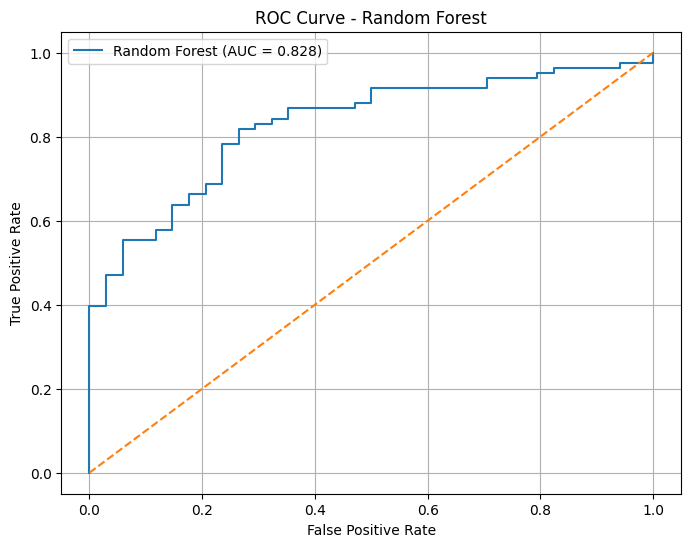

ROC-AUC Score: 0.828


In [288]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC values
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)

# Calculate AUC
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 3))

In [289]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_results = cross_validate(
    best_rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = cv_results[f'test_{metric}']

    print(
        f"{metric}: {scores.mean():.3f} "
        f"(+/- {scores.std():.3f})"
    )

accuracy: 0.682 (+/- 0.019)
balanced_accuracy: 0.684 (+/- 0.036)
precision: 0.850 (+/- 0.045)
recall: 0.682 (+/- 0.069)
f1: 0.753 (+/- 0.026)
roc_auc: 0.727 (+/- 0.037)


In [290]:

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Store models
models = {
    'Random Forest': best_rf_model,
    'Logistic Regression': best_lr_model,
    'SVM': best_svm_model
}

results = []

# Evaluate each model
for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    results.append({
        'Model': model_name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean()
    })

# Display comparison
comparison_df = pd.DataFrame(results)

print(comparison_df.round(3))


                 Model  Accuracy  Balanced Accuracy  Precision  Recall  \
0        Random Forest     0.682              0.684      0.850   0.682   
1  Logistic Regression     0.601              0.678      0.905   0.499   
2                  SVM     0.609              0.686      0.906   0.508   

   F1 Score  ROC-AUC  
0     0.753    0.727  
1     0.637    0.718  
2     0.645    0.718  


In [291]:
print(best_rf_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age', 'Total_Bilirubin',
                                                   'Direct_Bilirubin',
                                                   'Alkaline_Phosphotase',
                                                   'Alamine_Aminotransferase',
                                                   'Aspartate_Aminotransferase',
                                                   'Total_Proteins', 'Albumin',
                                                   'Albumin_and_Globulin_Ratio']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                               

In [292]:
import joblib

# Save the complete Random Forest pipeline
joblib.dump(best_rf_model, "liver_disease_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [293]:
# Load saved model
loaded_model = joblib.load("liver_disease_model.pkl")

print("Model loaded successfully!")
print(loaded_model)

Model loaded successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age', 'Total_Bilirubin',
                                                   'Direct_Bilirubin',
                                                   'Alkaline_Phosphotase',
                                                   'Alamine_Aminotransferase',
                                                   'Aspartate_Aminotransferase',
                                                   'Total_Proteins', 'Albumin',
                                                   'Albumin_and_Globulin_Ratio']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                    

In [294]:
# Predict using saved model
sample_predictions = loaded_model.predict(X_test.head(5))

print("Predictions:", sample_predictions)

Predictions: [1 0 1 1 0]


In [295]:
sample_probabilities = loaded_model.predict_proba(X_test.head(5))

print(sample_probabilities)

[[0.26861775 0.73138225]
 [0.5629221  0.4370779 ]
 [0.41705024 0.58294976]
 [0.08099634 0.91900366]
 [0.52227229 0.47772771]]


In [296]:
pip install streamlit joblib pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [297]:
print(X_train.columns.tolist())

['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin', 'Albumin_and_Globulin_Ratio']
